# Deep Round 3 Analysis — Options Trading
## VEV Call Options on VELVETFRUIT_EXTRACT + HYDROGEL_PACK market making

Products discovered in round 3 data:
- **`VELVETFRUIT_EXTRACT`** — underlying asset (~5250)
- **`VEV_K`** (K = 4000–6500) — call options on VELVETFRUIT_EXTRACT with strike K
- **`HYDROGEL_PACK`** — separate market-making product (~10000), uncorrelated with VEV

Run all cells top-to-bottom. Edit the config cells in Section 0 to adjust train/val split or T assumption.


## Section 0 — Imports & Config

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import math, warnings, itertools
warnings.filterwarnings('ignore')
%matplotlib inline
plt.rcParams['figure.figsize'] = (14, 4)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.4
plt.rcParams['axes.facecolor'] = '#fafafa'


In [2]:
# ── ROUND 3 DATA CONFIG ───────────────────────────────────────────────────────
ROUND    = 3
DATA_DIR = "ROUND_3"
DAYS     = [0, 1, 2]

# Products (hardcoded from data — auto-verified in loading cell)
UNDERLYING      = "VELVETFRUIT_EXTRACT"
OPTION_STRIKES  = [4000, 4500, 5000, 5100, 5200, 5300, 5400, 5500, 6000, 6500]
OPTION_NAMES    = [f"VEV_{k}" for k in OPTION_STRIKES]
HYDROGEL        = "HYDROGEL_PACK"
ALL_PRODUCTS    = [UNDERLYING, HYDROGEL] + OPTION_NAMES

# ── OPTIONS PRICING PARAMETERS ────────────────────────────────────────────────
# T_BASE = 1.0 calibrated empirically: with T=1.0 all strikes yield IV ≈ 0.032
# (flat vol surface). T represents the Black-Scholes time-to-expiry reference.
# If options expire at end of Round 3 (tick 30000 of competition round),
# T decays linearly from T_BASE at tick 0 to 0 at tick 30000.
T_BASE         = 1.0      # T at tick 0 of day 0  ← adjust if wiki gives a different expiry
TOTAL_TICKS    = 30_000   # 3 days × 10000 ticks
IV_ROLL_N      = 500      # rolling window for IV z-score and smoothing


In [3]:
# ── TRAIN / VALIDATION SPLIT ──────────────────────────────────────────────────
# Contiguous: rows with (day, timestamp) <= TRAIN_END are train; rest are val.
# Default: days 0-1 train, day 2 val.
TRAIN_END: tuple[int, int] = (1, 999900)

def _split(df: pd.DataFrame):
    mask = [(d, t) <= TRAIN_END for d, t in zip(df['day'], df['timestamp'])]
    return df[mask].copy(), df[[not m for m in mask]].copy()

DAY_COLORS = {0:'steelblue', 1:'darkorange', 2:'crimson', -1:'purple', -2:'forestgreen'}


In [4]:
# ── DATA LOADING ──────────────────────────────────────────────────────────────
def _load_prices(day):
    df = pd.read_csv(f"{DATA_DIR}/prices_round_{ROUND}_day_{day}.csv", sep=";")
    df['day'] = day
    num = [c for c in df.columns
           if 'price' in c or 'volume' in c or c in ('mid_price','profit_and_loss')]
    for c in num:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    return df

def _load_trades(day):
    df = pd.read_csv(f"{DATA_DIR}/trades_round_{ROUND}_day_{day}.csv", sep=";")
    df['day'] = day
    df['price']    = pd.to_numeric(df['price'],    errors='coerce')
    df['quantity'] = pd.to_numeric(df['quantity'], errors='coerce')
    return df

prices_all = pd.concat([_load_prices(d) for d in DAYS], ignore_index=True)
trades_all = pd.concat([_load_trades(d) for d in DAYS], ignore_index=True)

# Add global tick index (continuous across days) and T
prices_all = prices_all.sort_values(['day','timestamp']).reset_index(drop=True)
prices_all['global_tick'] = range(len(prices_all))
# T decays from T_BASE at tick 0 to 0 at TOTAL_TICKS (per product independently)
prices_all['tick_num'] = prices_all.groupby('product').cumcount()
prices_all['T'] = np.maximum(T_BASE * (1 - prices_all['tick_num'] / TOTAL_TICKS), 1e-6)

prices_train, prices_val = _split(prices_all)
trades_train, trades_val = _split(trades_all)

discovered = sorted(prices_all['product'].unique())
print(f"Products in data: {discovered}")
assert set(ALL_PRODUCTS) == set(discovered), f"Mismatch: {set(ALL_PRODUCTS) ^ set(discovered)}"
print(f"\nLoaded {len(prices_all):,} price rows | {len(trades_all):,} trade rows")
print(f"Train: {len(prices_train):,} rows (days {sorted(prices_train['day'].unique())})")
print(f"Val  : {len(prices_val):,}  rows (days {sorted(prices_val['day'].unique())})")


Products in data: ['HYDROGEL_PACK', 'VELVETFRUIT_EXTRACT', 'VEV_4000', 'VEV_4500', 'VEV_5000', 'VEV_5100', 'VEV_5200', 'VEV_5300', 'VEV_5400', 'VEV_5500', 'VEV_6000', 'VEV_6500']

Loaded 360,000 price rows | 4,048 trade rows
Train: 240,000 rows (days [0, 1])
Val  : 120,000  rows (days [2])


## Section 1 — Black-Scholes Toolkit

Zero-rate Black-Scholes implemented with pure numpy/math (no scipy).
The norm_cdf uses the Abramowitz-Stegun approximation (max error 1.5e-7) — same as top P3 teams.


In [5]:
# ── BLACK-SCHOLES IMPLEMENTATION ─────────────────────────────────────────────
def norm_cdf(x: float) -> float:
    """Abramowitz-Stegun, max error 1.5e-7."""
    a1,a2,a3,a4,a5 = 0.254829592,-0.284496736,1.421413741,-1.453152027,1.061405429
    p = 0.3275911
    sign = 1 if x >= 0 else -1
    x = abs(x) / math.sqrt(2.0)
    t = 1.0 / (1.0 + p*x)
    y = 1.0 - (((((a5*t+a4)*t)+a3)*t+a2)*t+a1)*t*math.exp(-x*x)
    return 0.5*(1.0 + sign*y)

def bs_call(S: float, K: float, T: float, sigma: float) -> float:
    """Zero-rate Black-Scholes call price."""
    if T <= 0 or sigma <= 0: return max(S - K, 0.0)
    d1 = (math.log(S/K) + 0.5*sigma**2*T) / (sigma*math.sqrt(T))
    d2 = d1 - sigma*math.sqrt(T)
    return S*norm_cdf(d1) - K*norm_cdf(d2)

def bs_delta(S: float, K: float, T: float, sigma: float) -> float:
    """N(d1) — fraction of underlying per 1 option contract."""
    if T <= 0 or sigma <= 0: return 1.0 if S > K else 0.0
    d1 = (math.log(S/K) + 0.5*sigma**2*T) / (sigma*math.sqrt(T))
    return norm_cdf(d1)

def bs_gamma(S: float, K: float, T: float, sigma: float) -> float:
    """Rate of change of delta with respect to S."""
    if T <= 0 or sigma <= 0: return 0.0
    d1 = (math.log(S/K) + 0.5*sigma**2*T) / (sigma*math.sqrt(T))
    return math.exp(-0.5*d1**2) / (S * sigma * math.sqrt(T) * math.sqrt(2*math.pi))

def bs_theta(S: float, K: float, T: float, sigma: float) -> float:
    """Daily time decay (per 1/365 year)."""
    if T <= 0 or sigma <= 0: return 0.0
    d1 = (math.log(S/K) + 0.5*sigma**2*T) / (sigma*math.sqrt(T))
    d2 = d1 - sigma*math.sqrt(T)
    return -(S * math.exp(-0.5*d1**2) * sigma) / (2 * math.sqrt(T) * math.sqrt(2*math.pi)) / 365

def implied_vol(mkt_price: float, S: float, K: float, T: float,
                tol: float = 1e-6, max_iter: int = 100):
    """Bisection IV inversion. Returns None if no solution in [1e-6, 5.0]."""
    if mkt_price <= max(S - K, 0.0): return 1e-9   # at or below intrinsic
    lo, hi = 1e-6, 5.0
    if bs_call(S, K, T, hi) < mkt_price: return None  # price above BS upper bound
    for _ in range(max_iter):
        mid = (lo + hi) / 2
        if bs_call(S, K, T, mid) < mkt_price: lo = mid
        else:                                  hi = mid
        if hi - lo < tol: return (lo + hi) / 2
    return (lo + hi) / 2

# Sanity check — should print ~7.9656
test = bs_call(100, 100, 1.0, 0.2)
print(f"BS sanity: bs_call(100,100,1,0.2) = {test:.4f}  (expected 7.9656)")

# Verify T=1 calibration against round 3 data
S_ref = 5250.10
print(f"\nCalibration check (S={S_ref}, T=1.0):")
print(f"{'Strike':<10} {'mkt_mid':>8} {'BS(IV=0.032)':>14} {'diff':>8}")
sigma_ref = 0.032
for k in [5000, 5100, 5200, 5300, 5400, 5500]:
    mkt = prices_all[prices_all['product']==f'VEV_{k}']['mid_price'].mean()
    bs  = bs_call(S_ref, k, 1.0, sigma_ref)
    print(f"  VEV_{k}   {mkt:>8.2f}  {bs:>14.2f}  {mkt-bs:>8.2f}")


BS sanity: bs_call(100,100,1,0.2) = 7.9656  (expected 7.9656)

Calibration check (S=5250.1, T=1.0):
Strike      mkt_mid   BS(IV=0.032)     diff
  VEV_5000     255.02          254.63      0.39
  VEV_5100     166.81          166.53      0.27
  VEV_5200      95.55           94.72      0.83
  VEV_5300      46.76           45.31      1.45
  VEV_5400      15.95           17.76     -1.80
  VEV_5500       6.64            5.60      1.04


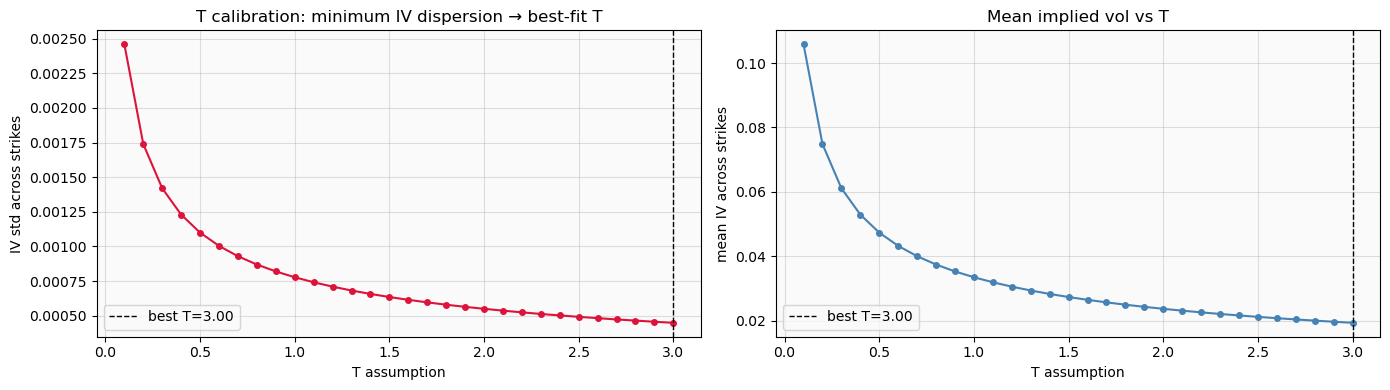

Best-fit T = 3.00  →  mean IV = 0.01933
Using T_BASE = 1.0 from config (override above if best_T differs significantly)


In [6]:
# ── T CALIBRATION SCAN ───────────────────────────────────────────────────────
# For each candidate T, compute IV for all liquid strikes (5000-5500) and
# measure the std of IV across strikes. The T that gives the flattest vol surface
# (min IV std) is the best-fit time-to-expiry assumption.
#
# Rationale: a flat vol surface under the "true" T means the market is using a
# single implied vol for all strikes, consistent with lognormal BS pricing.
usable_strikes = [5000, 5100, 5200, 5300, 5400, 5500]
S_cal = prices_train[prices_train['product']==UNDERLYING]['mid_price'].mean()

T_candidates = np.arange(0.1, 3.01, 0.1)
iv_stds = []
iv_means = []
for T_cand in T_candidates:
    ivs = []
    for k in usable_strikes:
        mp = prices_train[prices_train['product']==f'VEV_{k}']['mid_price'].mean()
        v  = implied_vol(mp, S_cal, k, T_cand)
        if v: ivs.append(v)
    iv_stds.append(np.std(ivs) if ivs else np.nan)
    iv_means.append(np.mean(ivs) if ivs else np.nan)

best_T = T_candidates[np.nanargmin(iv_stds)]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
ax1.plot(T_candidates, iv_stds, 'o-', markersize=4, color='crimson')
ax1.axvline(best_T, color='black', linestyle='--', linewidth=1, label=f'best T={best_T:.2f}')
ax1.set_xlabel("T assumption"); ax1.set_ylabel("IV std across strikes")
ax1.set_title("T calibration: minimum IV dispersion → best-fit T")
ax1.legend()
ax2.plot(T_candidates, iv_means, 'o-', markersize=4, color='steelblue')
ax2.axvline(best_T, color='black', linestyle='--', linewidth=1, label=f'best T={best_T:.2f}')
ax2.set_xlabel("T assumption"); ax2.set_ylabel("mean IV across strikes")
ax2.set_title("Mean implied vol vs T")
ax2.legend()
plt.tight_layout(); plt.show()
print(f"Best-fit T = {best_T:.2f}  →  mean IV = {iv_means[np.nanargmin(iv_stds)]:.5f}")
print(f"Using T_BASE = {T_BASE} from config (override above if best_T differs significantly)")


## Section 2 — Underlying: VELVETFRUIT_EXTRACT

Characterize the underlying before analyzing options on it.
Key questions: is it stable (good for fixed-fair-value market making)?
What is its realized volatility? Does its order book show a "wall mid"?


In [ ]:
vev = prices_all[prices_all['product']==UNDERLYING].copy().sort_values(['day','timestamp'])
vev['spread']     = vev['ask_price_1'] - vev['bid_price_1']
vev['ret']        = vev['mid_price'].pct_change()
vev['roll_vol']   = vev['mid_price'].rolling(200, min_periods=20).std()
vev['roll_mean']  = vev['mid_price'].rolling(500, min_periods=50).mean()

split_tick = sum(k <= TRAIN_END for k in zip(vev['day'], vev['timestamp']))
vev['tick'] = range(len(vev))

fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=True)

for day in DAYS:
    seg = vev[vev['day']==day]
    c   = DAY_COLORS[day]
    axes[0].plot(seg['tick'], seg['mid_price'], color=c, linewidth=0.75, label=f"day {day}")
axes[0].plot(vev['tick'], vev['roll_mean'], 'k--', linewidth=1.0, alpha=0.7, label='rolling mean (500)')
axes[0].axvline(split_tick, color='gray', linestyle=':', linewidth=1.5, label='train|val')
axes[0].set_title("VELVETFRUIT_EXTRACT — mid_price"); axes[0].legend(fontsize=8); axes[0].set_ylabel("price")

for day in DAYS:
    seg = vev[vev['day']==day]
    axes[1].plot(seg['tick'], seg['spread'], color=DAY_COLORS[day], linewidth=0.6, alpha=0.85)
axes[1].axvline(split_tick, color='gray', linestyle=':', linewidth=1.5)
axes[1].set_ylabel("bid-ask spread")

axes[2].plot(vev['tick'], vev['roll_vol'], color='teal', linewidth=0.8)
axes[2].axvline(split_tick, color='gray', linestyle=':', linewidth=1.5)
axes[2].set_ylabel("rolling 200-tick σ")

axes[3].plot(vev['tick'], vev['ret'], color='gray', linewidth=0.4, alpha=0.7)
axes[3].axhline(0, color='black', linewidth=0.5)
axes[3].axvline(split_tick, color='gray', linestyle=':', linewidth=1.5)
axes[3].set_ylabel("returns"); axes[3].set_xlabel("tick")
plt.tight_layout(); plt.show()

vev_tr = vev[vev['tick'] < split_tick]
print(f"Underlying stats (training):")
print(f"  mid_price: mean={vev_tr['mid_price'].mean():.2f}  std={vev_tr['mid_price'].std():.2f}")
print(f"  spread   : mean={vev_tr['spread'].mean():.3f}  std={vev_tr['spread'].std():.3f}")
print(f"  return autocorr lag1={vev_tr['ret'].autocorr(1):.4f}  lag5={vev_tr['ret'].autocorr(5):.4f}")
print(f"  ann. realized vol (T=1 scaling): {vev_tr['ret'].std()*np.sqrt(10000):.5f}")


In [ ]:
# Wall mid for VELVETFRUIT_EXTRACT
# Wall mid = average of the max-volume bid and max-volume ask levels.
# For stable assets it's a better fair value estimate than raw mid_price.
def wall_mid(row):
    bv = [(row.get(f'bid_volume_{i}') or 0, row.get(f'bid_price_{i}', np.nan)) for i in range(1,4)]
    av = [(row.get(f'ask_volume_{i}') or 0, row.get(f'ask_price_{i}', np.nan)) for i in range(1,4)]
    bb = max(bv, key=lambda x: x[0])[1]
    ba = max(av, key=lambda x: x[0])[1]
    return (bb + ba) / 2 if not (np.isnan(bb) or np.isnan(ba)) else np.nan

vev['wall_mid'] = vev.apply(wall_mid, axis=1)
diff = vev['wall_mid'] - vev['mid_price']

fig, (a0, a1) = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
for day in DAYS:
    seg = vev[vev['day']==day]
    a0.plot(seg['tick'], seg['mid_price'], color=DAY_COLORS[day], linewidth=0.7, label=f"day {day}")
a0.plot(vev['tick'], vev['wall_mid'], color='darkorange', linewidth=1.0, alpha=0.85,
        label='wall_mid', zorder=3)
a0.set_title("VELVETFRUIT_EXTRACT — wall_mid vs mid_price"); a0.legend(fontsize=8)
a1.plot(vev['tick'], diff, color='purple', linewidth=0.7)
a1.axhline(0, color='gray', linewidth=0.5)
a1.set_ylabel("wall_mid − mid_price"); a1.set_xlabel("tick")
plt.tight_layout(); plt.show()
print(f"wall_mid − mid_price: mean={diff.mean():.4f}  std={diff.std():.4f}  max_abs={diff.abs().max():.4f}")


## Section 3 — HYDROGEL_PACK (Independent Market-Making Product)

HYDROGEL_PACK has **zero return-correlation with VELVETFRUIT_EXTRACT** (r ≈ 0.006).
It is a completely separate product requiring its own strategy. Analyze it independently.


In [ ]:
hydr = prices_all[prices_all['product']==HYDROGEL].copy().sort_values(['day','timestamp'])
hydr['spread']    = hydr['ask_price_1'] - hydr['bid_price_1']
hydr['ret']       = hydr['mid_price'].pct_change()
hydr['roll_vol']  = hydr['mid_price'].rolling(200, min_periods=20).std()
hydr['wall_mid_h']= hydr.apply(wall_mid, axis=1)
split_tick_h = sum(k <= TRAIN_END for k in zip(hydr['day'], hydr['timestamp']))
hydr['tick'] = range(len(hydr))

fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
for day in DAYS:
    seg = hydr[hydr['day']==day]
    axes[0].plot(seg['tick'], seg['mid_price'], color=DAY_COLORS[day], linewidth=0.75, label=f"day {day}")
axes[0].plot(hydr['tick'], hydr['wall_mid_h'], color='darkorange', linewidth=1.0, alpha=0.85, label='wall_mid')
axes[0].axvline(split_tick_h, color='gray', linestyle=':', linewidth=1.5, label='train|val')
axes[0].set_title("HYDROGEL_PACK — price & wall_mid"); axes[0].legend(fontsize=8); axes[0].set_ylabel("price")

for day in DAYS:
    seg = hydr[hydr['day']==day]
    axes[1].plot(seg['tick'], seg['spread'], color=DAY_COLORS[day], linewidth=0.6)
axes[1].axvline(split_tick_h, color='gray', linestyle=':', linewidth=1.5)
axes[1].set_ylabel("bid-ask spread")

axes[2].plot(hydr['tick'], hydr['roll_vol'], color='teal', linewidth=0.8)
axes[2].axvline(split_tick_h, color='gray', linestyle=':', linewidth=1.5)
axes[2].set_ylabel("rolling 200-tick σ"); axes[2].set_xlabel("tick")
plt.tight_layout(); plt.show()

h_tr = hydr[hydr['tick'] < split_tick_h]
print(f"HYDROGEL stats (training):")
print(f"  mid_price : mean={h_tr['mid_price'].mean():.2f}  std={h_tr['mid_price'].std():.2f}")
print(f"  spread    : mean={h_tr['spread'].mean():.3f}  std={h_tr['spread'].std():.3f}")
print(f"  return autocorr lag1={h_tr['ret'].autocorr(1):.4f}")
print(f"  VEV/HYDR return corr: {h_tr['ret'].corr(vev[vev['tick']<split_tick_h]['ret'].values):.4f}")


In [ ]:
# HYDROGEL order book depth — look for persistent wall levels
first_day = 0
ph = hydr[hydr['day']==first_day].copy()
for c in ['bid_volume_1','bid_volume_2','bid_volume_3','ask_volume_1','ask_volume_2','ask_volume_3']:
    ph[c] = ph[c].fillna(0)
ts = ph['timestamp'].values

fig, ax = plt.subplots(figsize=(14, 4))
ax.stackplot(ts,  ph['bid_volume_1'],  ph['bid_volume_2'],  ph['bid_volume_3'],
             labels=['bid L1','bid L2','bid L3'],
             colors=['#4a90d9','#7bb3e8','#b3d4f5'], alpha=0.85)
ax.stackplot(ts, -ph['ask_volume_1'], -ph['ask_volume_2'], -ph['ask_volume_3'],
             labels=['ask L1','ask L2','ask L3'],
             colors=['#e05c5c','#ec8d8d','#f5bebe'], alpha=0.85)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title(f"HYDROGEL_PACK — order book depth (day {first_day})")
ax.set_ylabel("volume (bids ↑, asks ↓)"); ax.set_xlabel("timestamp")
ax.legend(loc='upper right', fontsize=8, ncol=6); plt.tight_layout(); plt.show()


## Section 4 — Options Overview: Price, Intrinsic Value, Time Value

For each strike, decompose `mid_price = intrinsic + time_value` where intrinsic = max(S−K, 0).

- **Deep ITM** (VEV_4000, VEV_4500): intrinsic dominates, delta ≈ 1
- **Near ATM** (VEV_5000–5300): time value peaks, most sensitive to vol
- **OTM** (VEV_5400–5500): pure time value, high vol sensitivity
- **Deep OTM** (VEV_6000, VEV_6500): floor-priced at 0.5, effectively worthless


In [ ]:
# Build a wide-format options summary aligned with underlying price
vev_s = prices_all[prices_all['product']==UNDERLYING].set_index(['day','timestamp'])['mid_price'].rename('S')

summary_rows = []
for k in OPTION_STRIKES:
    opt = prices_all[prices_all['product']==f'VEV_{k}'].set_index(['day','timestamp'])['mid_price']
    df  = pd.DataFrame({'C': opt, 'S': vev_s}).dropna()
    df['intrinsic'] = (df['S'] - k).clip(lower=0)
    df['time_val']  = df['C'] - df['intrinsic']
    df['moneyness'] = df['S'] / k
    summary_rows.append({'K': k, 'product': f'VEV_{k}',
                         'mean_C':  df['C'].mean(),
                         'mean_intrinsic': df['intrinsic'].mean(),
                         'mean_time_val': df['time_val'].mean(),
                         'mean_moneyness': df['moneyness'].mean(),
                         'C_std': df['C'].std()})
opt_summary = pd.DataFrame(summary_rows)
print(opt_summary[['K','mean_C','mean_intrinsic','mean_time_val','mean_moneyness','C_std']]      .rename(columns={'mean_C':'avg_mid','mean_intrinsic':'avg_intrinsic',
                       'mean_time_val':'avg_time_val','mean_moneyness':'avg_S/K',
                       'C_std':'C_std'})      .to_string(index=False, float_format=lambda x: f'{x:.2f}'))


In [ ]:
# Plot time value by strike (bar chart) and option mid_price series
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

liquid = [k for k in OPTION_STRIKES if k not in (6000, 6500)]
tv_means  = [opt_summary[opt_summary['K']==k]['mean_time_val'].values[0]  for k in liquid]
c_means   = [opt_summary[opt_summary['K']==k]['mean_C'].values[0]         for k in liquid]
int_means = [opt_summary[opt_summary['K']==k]['mean_intrinsic'].values[0] for k in liquid]

x = np.arange(len(liquid))
axes[0].bar(x, int_means, label='intrinsic',   color='steelblue', alpha=0.8)
axes[0].bar(x, tv_means,  bottom=int_means, label='time value', color='darkorange', alpha=0.8)
axes[0].set_xticks(x); axes[0].set_xticklabels([f'VEV_{k}' for k in liquid], rotation=30)
axes[0].set_ylabel("mid_price"); axes[0].set_title("Option price decomposition (avg over all data)")
axes[0].legend()

# Time value per day — shows theta decay
day_labels = []
for k in [5000, 5200, 5300, 5400]:
    tv_by_day = []
    for day in DAYS:
        sd  = prices_all[(prices_all['product']==f'VEV_{k}') & (prices_all['day']==day)]['mid_price'].mean()
        s_d = prices_all[(prices_all['product']==UNDERLYING)  & (prices_all['day']==day)]['mid_price'].mean()
        tv_by_day.append(max(sd - max(s_d - k, 0), 0))
    axes[1].plot(DAYS, tv_by_day, 'o-', label=f'VEV_{k}')
axes[1].set_xlabel("day"); axes[1].set_ylabel("avg time value")
axes[1].set_title("Time value decay across days (theta)")
axes[1].legend(); plt.tight_layout(); plt.show()


In [ ]:
# Option price series — all liquid strikes on one plot per day
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
liquid_strikes = [k for k in OPTION_STRIKES if k not in (6000, 6500)]
cmap = plt.cm.viridis
colors_k = {k: cmap(i/len(liquid_strikes)) for i,k in enumerate(liquid_strikes)}

for di, day in enumerate(DAYS):
    ax = axes[di]
    vev_d = prices_all[(prices_all['product']==UNDERLYING) & (prices_all['day']==day)].set_index('timestamp')['mid_price']
    for k in liquid_strikes:
        opt_d = prices_all[(prices_all['product']==f'VEV_{k}') & (prices_all['day']==day)].set_index('timestamp')['mid_price']
        ax.plot(opt_d.index, opt_d.values, linewidth=0.7, color=colors_k[k], label=f'VEV_{k}')
    ax.set_title(f"Day {day} — all option mid_prices")
    ax.set_xlabel("timestamp"); ax.set_ylabel("option price") if di==0 else None
handles = [plt.Line2D([0],[0],color=colors_k[k],label=f'VEV_{k}') for k in liquid_strikes]
axes[-1].legend(handles=handles, fontsize=7, loc='upper right')
plt.tight_layout(); plt.show()


## Section 5 — Implied Volatility Surface

Compute IV per tick per strike. Produces:
1. IV time series for each liquid strike
2. Vol smile (IV vs moneyness) at multiple time snapshots
3. Vol surface heatmap: IV vs (strike, tick)
4. IV z-score series (trading signal for IV mean reversion)

The primary edge in Prosperity options has consistently been **IV mean reversion** — not directional bets.
Do NOT trade the underlying directionally alongside options (jmerle P2 lesson).


In [ ]:
# Compute IV for every tick for every liquid strike (training data only for now)
iv_liquid = [k for k in OPTION_STRIKES if k not in (4000, 4500, 6000, 6500)]
# Deep ITM (4000/4500) have near-zero time value → IV computation unstable
# Deep OTM (6000/6500) are floored at 0.5 → artificially low price

iv_frames = {}
for k in iv_liquid:
    opt = prices_train[(prices_train['product']==f'VEV_{k}')].copy()              .sort_values(['day','timestamp']).reset_index(drop=True)
    und = prices_train[prices_train['product']==UNDERLYING]              .set_index(['day','timestamp'])['mid_price']
    opt = opt.join(und.rename('S'), on=['day','timestamp'])
    opt['IV'] = opt.apply(
        lambda r: implied_vol(r['mid_price'], r['S'], k, r['T'])
                  if (pd.notna(r['mid_price']) and pd.notna(r['S']) and r['S'] > 0) else np.nan,
        axis=1)
    opt['tick'] = range(len(opt))
    iv_frames[k] = opt
    valid = opt['IV'].dropna()
    print(f"VEV_{k}: IV mean={valid.mean():.5f}  std={valid.std():.5f}  "
          f"min={valid.min():.5f}  max={valid.max():.5f}  ({valid.isna().sum()} NaN)")


In [ ]:
# IV time series — all liquid strikes on one plot, colored by strike
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
colors_iv = plt.cm.plasma(np.linspace(0.1, 0.9, len(iv_liquid)))

split_tick_iv = len(iv_frames[iv_liquid[0]][
    list(zip(iv_frames[iv_liquid[0]]['day'],
             iv_frames[iv_liquid[0]]['timestamp'])).index.__class__  # placeholder
])
# Actually just use the length of training frames
split_ticks = {k: len(iv_frames[k]) for k in iv_liquid}  # training only anyway

for i, k in enumerate(iv_liquid):
    f   = iv_frames[k]
    col = colors_iv[i]
    axes[0].plot(f['tick'], f['IV'], linewidth=0.6, color=col, alpha=0.85, label=f'VEV_{k}')

axes[0].set_ylabel("Implied Vol (IV)"); axes[0].legend(fontsize=8, ncol=3)
axes[0].set_title(f"IV time series per strike (T={T_BASE})")

# Plot IV deviation from its own rolling mean per strike
for i, k in enumerate(iv_liquid):
    f     = iv_frames[k].copy()
    f['IV_roll'] = f['IV'].rolling(IV_ROLL_N, min_periods=50).mean()
    f['IV_dev']  = f['IV'] - f['IV_roll']
    axes[1].plot(f['tick'], f['IV_dev'], linewidth=0.5, color=colors_iv[i], alpha=0.75, label=f'VEV_{k}')
axes[1].axhline(0, color='black', linewidth=0.5)
axes[1].set_ylabel(f"IV − rolling mean ({IV_ROLL_N})"); axes[1].set_xlabel("tick (training)")
axes[1].legend(fontsize=8, ncol=3)
plt.tight_layout(); plt.show()


In [ ]:
# Vol smile — IV vs moneyness at multiple time snapshots
snapshots = [(0, 0), (0, 500000), (1, 0), (1, 500000), (2, 0), (2, 500000)]
snapshot_labels = [f"d{d} t{t//1000}k" for d,t in snapshots]

und_price_map = {(d,t): prices_all[(prices_all['product']==UNDERLYING) &
                                    (prices_all['day']==d) &
                                    (prices_all['timestamp']==t)]['mid_price'].values
                 for d,t in snapshots}

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for si, (day, ts) in enumerate(snapshots):
    ax = axes[si]
    S_arr = und_price_map[(day, ts)]
    if len(S_arr) == 0:
        ax.set_title(f"No data: {snapshot_labels[si]}"); continue
    S_snap = S_arr[0]

    smile_k, smile_iv, smile_mn = [], [], []
    for k in iv_liquid:
        opt_p = prices_all[(prices_all['product']==f'VEV_{k}') &
                           (prices_all['day']==day) &
                           (prices_all['timestamp']==ts)]['mid_price'].values
        T_row = prices_all[(prices_all['product']==f'VEV_{k}') &
                           (prices_all['day']==day) &
                           (prices_all['timestamp']==ts)]['T'].values
        if len(opt_p) and pd.notna(opt_p[0]) and len(T_row):
            v = implied_vol(opt_p[0], S_snap, k, float(T_row[0]))
            if v:
                smile_k.append(k); smile_iv.append(v); smile_mn.append(S_snap/k)

    if smile_k:
        ax.plot(smile_mn, smile_iv, 'o-', markersize=6, color='teal', linewidth=1.2)
        for kk, iv_v, mn_v in zip(smile_k, smile_iv, smile_mn):
            ax.annotate(str(kk), (mn_v, iv_v), textcoords='offset points',
                        xytext=(0,6), fontsize=7, ha='center')
    ax.axvline(1.0, color='gray', linestyle='--', linewidth=0.8, label='ATM')
    ax.set_title(f"Vol smile — {snapshot_labels[si]}  (S={S_snap:.0f})")
    ax.set_xlabel("moneyness (S/K)"); ax.set_ylabel("IV") if si % 3 == 0 else None
    ax.legend(fontsize=7)
plt.suptitle("Volatility smile across time snapshots", fontsize=12, y=1.01)
plt.tight_layout(); plt.show()


In [ ]:
# Vol surface heatmap — IV vs (strike, time)
# Rows = strikes, columns = time → color = IV level
from matplotlib.colors import Normalize

n_ticks = len(iv_frames[iv_liquid[0]])
# Downsample to every 100 ticks for readability
step = 50
tick_idx = range(0, n_ticks, step)

surface = np.full((len(iv_liquid), len(tick_idx)), np.nan)
for ri, k in enumerate(iv_liquid):
    iv_s = iv_frames[k]['IV'].values
    for ci, ti in enumerate(tick_idx):
        if ti < len(iv_s): surface[ri, ci] = iv_s[ti]

fig, ax = plt.subplots(figsize=(16, 5))
im = ax.imshow(surface, aspect='auto', cmap='RdYlGn_r',
               norm=Normalize(vmin=np.nanpercentile(surface, 5),
                              vmax=np.nanpercentile(surface, 95)))
ax.set_yticks(range(len(iv_liquid)))
ax.set_yticklabels([f'VEV_{k}' for k in iv_liquid])
xtick_pos  = list(range(0, len(tick_idx), max(1, len(tick_idx)//20)))
xtick_labs = [f"d{iv_frames[iv_liquid[0]]['day'].iloc[min(t*step, n_ticks-1)]}/"
              f"{iv_frames[iv_liquid[0]]['timestamp'].iloc[min(t*step, n_ticks-1)]//1000}k"
              for t in xtick_pos]
ax.set_xticks(xtick_pos); ax.set_xticklabels(xtick_labs, rotation=45, ha='right', fontsize=7)
plt.colorbar(im, ax=ax, label="Implied Vol")
ax.set_title(f"IV surface heatmap — darker green = lower IV, darker red = higher IV")
plt.tight_layout(); plt.show()


In [ ]:
# IV z-score per strike — the primary trading signal
# Entry: buy option when IV z-score < -2 (IV unusually low vs its own history)
#        sell option when IV z-score > +2 (IV unusually high)
fig, axes = plt.subplots(len(iv_liquid), 1, figsize=(14, 3*len(iv_liquid)), sharex=True)
if len(iv_liquid) == 1: axes = [axes]

for i, k in enumerate(iv_liquid):
    f = iv_frames[k].copy()
    f['IV_mean'] = f['IV'].rolling(IV_ROLL_N, min_periods=50).mean()
    f['IV_std']  = f['IV'].rolling(IV_ROLL_N, min_periods=50).std()
    f['IV_z']    = (f['IV'] - f['IV_mean']) / f['IV_std']
    iv_frames[k]['IV_z']    = f['IV_z'].values
    iv_frames[k]['IV_mean'] = f['IV_mean'].values

    axes[i].plot(f['tick'], f['IV_z'], linewidth=0.7, color=colors_iv[i])
    axes[i].axhline(2,   color='red',   linestyle='--', linewidth=0.9)
    axes[i].axhline(-2,  color='red',   linestyle='--', linewidth=0.9)
    axes[i].axhline(0.5, color='green', linestyle=':',  linewidth=0.7)
    axes[i].axhline(-0.5,color='green', linestyle=':',  linewidth=0.7)
    axes[i].set_ylabel(f"VEV_{k}
IV z"); axes[i].set_ylim(-5, 5)
    n_hi = (f['IV_z'] >  2).sum()
    n_lo = (f['IV_z'] < -2).sum()
    axes[i].set_title(f"VEV_{k} IV z-score  |  entries: {n_lo} sell-IV, {n_hi} buy-IV", fontsize=9)
axes[-1].set_xlabel("tick (training)")
plt.suptitle("IV z-scores per strike (entry ±2, exit ±0.5)", y=1.01, fontsize=12)
plt.tight_layout(); plt.show()


## Section 6 — Option vs Underlying: Empirical Delta & Gamma

Compare observed option price changes to BS delta prediction.
Large deviations from BS delta indicate either IV changes (vega) or model inadequacy.


In [ ]:
# Empirical delta per strike
vev_s_all = prices_train[prices_train['product']==UNDERLYING]                .set_index(['day','timestamp'])['mid_price']

print(f"{'Strike':<10} {'BS delta':>10} {'empirical δ':>13} {'corr(dC,dS)':>13}")
print("-"*50)
delta_rows = []
for k in iv_liquid:
    opt_s = prices_train[prices_train['product']==f'VEV_{k}']                .set_index(['day','timestamp'])['mid_price']
    df = pd.DataFrame({'C': opt_s, 'S': vev_s_all}).dropna()
    dC = df['C'].diff(); dS = df['S'].diff()
    mask = dS.abs() > 0
    emp_delta = (dC[mask] / dS[mask]).median()
    corr_val  = dC.corr(dS)
    # BS delta at mean S and mean IV
    iv_mean_k = iv_frames[k]['IV'].mean() if k in iv_frames else 0.032
    bs_d = bs_delta(df['S'].mean(), k, T_BASE, iv_mean_k)
    print(f"  VEV_{k}   {bs_d:>10.4f}  {emp_delta:>13.4f}  {corr_val:>13.4f}")
    delta_rows.append({'K':k, 'bs_delta':bs_d, 'emp_delta':emp_delta})

delta_df = pd.DataFrame(delta_rows)


In [ ]:
# Delta scatter: BS delta vs empirical delta
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.scatter(delta_df['K'], delta_df['bs_delta'],  color='steelblue', s=80, label='BS delta', zorder=3)
ax1.scatter(delta_df['K'], delta_df['emp_delta'], color='crimson',   s=80, marker='x', label='empirical δ', zorder=3)
ax1.set_xlabel("Strike K"); ax1.set_ylabel("delta")
ax1.set_title("BS delta vs empirical delta (dC/dS median) by strike")
ax1.legend()

# Show option price vs underlying price scatter for ATM-ish strikes
for k in [5200, 5300, 5400]:
    opt_s = prices_train[prices_train['product']==f'VEV_{k}']                .set_index(['day','timestamp'])['mid_price']
    df = pd.DataFrame({'C': opt_s, 'S': vev_s_all}).dropna()
    ax2.scatter(df['S'], df['C'], s=2, alpha=0.3, label=f'VEV_{k}')
    # Overlay BS theoretical line
    S_range = np.linspace(df['S'].min(), df['S'].max(), 100)
    iv_k = iv_frames[k]['IV'].mean() if k in iv_frames else 0.032
    bs_line = [bs_call(s, k, T_BASE, iv_k) for s in S_range]
    ax2.plot(S_range, bs_line, linewidth=1.5, label=f'BS VEV_{k}')
ax2.set_xlabel("S (VELVETFRUIT_EXTRACT)"); ax2.set_ylabel("option mid_price")
ax2.set_title("Option price vs underlying (scatter + BS curve)")
ax2.legend(fontsize=8)
plt.tight_layout(); plt.show()


In [ ]:
# Residual = option_mid - BS_theoretical_price
# If residuals are mean-reverting, this is a direct trading signal:
# buy option when residual < 0 (underpriced), sell when > 0 (overpriced)
fig, axes = plt.subplots(len(iv_liquid), 1, figsize=(14, 3*len(iv_liquid)), sharex=True)
if len(iv_liquid) == 1: axes = [axes]

for i, k in enumerate(iv_liquid):
    f    = iv_frames[k].copy()
    und  = prices_train[prices_train['product']==UNDERLYING]               .set_index(['day','timestamp'])['mid_price']
    f = f.join(und.rename('S'), on=['day','timestamp'])
    iv_k = f['IV'].mean()
    f['BS_price']  = f.apply(lambda r: bs_call(r['S'], k, r['T'], iv_k)
                              if pd.notna(r['S']) else np.nan, axis=1)
    f['residual']  = f['mid_price'] - f['BS_price']
    f['tick']      = range(len(f))

    axes[i].plot(f['tick'], f['residual'], linewidth=0.6, color=colors_iv[i])
    axes[i].axhline(0, color='black', linewidth=0.5)
    rsd = f['residual'].std()
    axes[i].axhline( 2*rsd, color='red',   linestyle='--', linewidth=0.8)
    axes[i].axhline(-2*rsd, color='red',   linestyle='--', linewidth=0.8)
    axes[i].set_ylabel(f"VEV_{k}
residual")
    ac1 = f['residual'].autocorr(1)
    axes[i].set_title(f"VEV_{k} — mid_price − BS(avg_IV) | autocorr={ac1:.3f}", fontsize=9)

axes[-1].set_xlabel("tick (training)")
plt.suptitle("Option price residual vs BS(mean IV) — dashed = ±2σ", y=1.01, fontsize=12)
plt.tight_layout(); plt.show()


## Section 7 — Greeks Across the Option Chain

Plot Delta, Gamma, and Theta for each liquid strike over time.

- **Delta**: net underlying exposure per contract — drives hedging requirement
- **Gamma**: rate of delta change — high near ATM, spikes as expiry approaches
- **Theta**: daily time decay — this is "rent" you pay for holding options long


In [ ]:
# Compute Delta, Gamma, Theta per tick per strike (using per-tick IV)
greeks_frames = {}
for k in iv_liquid:
    f   = iv_frames[k].copy()
    und = prices_train[prices_train['product']==UNDERLYING]              .set_index(['day','timestamp'])['mid_price']
    f   = f.join(und.rename('S'), on=['day','timestamp'])
    # Use per-tick IV where available; fall back to mean IV
    mean_iv = f['IV'].mean()
    f['iv_use'] = f['IV'].fillna(mean_iv)
    f['delta']  = f.apply(lambda r: bs_delta(r['S'], k, r['T'], r['iv_use'])
                           if pd.notna(r['S']) else np.nan, axis=1)
    f['gamma']  = f.apply(lambda r: bs_gamma(r['S'], k, r['T'], r['iv_use'])
                           if pd.notna(r['S']) else np.nan, axis=1)
    f['theta']  = f.apply(lambda r: bs_theta(r['S'], k, r['T'], r['iv_use'])
                           if pd.notna(r['S']) else np.nan, axis=1)
    f['tick']   = range(len(f))
    greeks_frames[k] = f

# Delta time series
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
for i, k in enumerate(iv_liquid):
    f = greeks_frames[k]
    axes[0].plot(f['tick'], f['delta'], linewidth=0.7, color=colors_iv[i], label=f'VEV_{k}')
    axes[1].plot(f['tick'], f['gamma'], linewidth=0.7, color=colors_iv[i])
    axes[2].plot(f['tick'], f['theta'], linewidth=0.7, color=colors_iv[i])
axes[0].set_ylabel("Delta"); axes[0].legend(fontsize=7, ncol=3)
axes[0].set_title("Greeks across option chain — training data")
axes[1].set_ylabel("Gamma")
axes[2].set_ylabel("Theta (per year)"); axes[2].set_xlabel("tick")
plt.tight_layout(); plt.show()


In [ ]:
# Static Greeks vs Strike (snapshot at training mean S and mean IV)
S_snap  = prices_train[prices_train['product']==UNDERLYING]['mid_price'].mean()
T_snap  = T_BASE * 0.5  # mid-life snapshot

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
K_range = np.linspace(4800, 5700, 200)
iv_snap = 0.032  # approximate mean IV

deltas = [bs_delta(S_snap, k, T_snap, iv_snap) for k in K_range]
gammas = [bs_gamma(S_snap, k, T_snap, iv_snap) for k in K_range]
thetas = [bs_theta(S_snap, k, T_snap, iv_snap) for k in K_range]

for k_pt in OPTION_STRIKES:
    if k_pt in (6000, 6500): continue
    iv_k = iv_frames[k_pt]['IV'].mean() if k_pt in iv_frames else iv_snap
    axes[0].axvline(k_pt, color='gray', linestyle=':', linewidth=0.7)
    axes[1].axvline(k_pt, color='gray', linestyle=':', linewidth=0.7)
    axes[2].axvline(k_pt, color='gray', linestyle=':', linewidth=0.7)

axes[0].plot(K_range, deltas, color='steelblue', linewidth=1.5)
axes[0].axvline(S_snap, color='red', linestyle='--', linewidth=1, label=f'S={S_snap:.0f}')
axes[0].set_title(f"Delta vs Strike (T={T_snap:.2f}, σ={iv_snap})"); axes[0].set_xlabel("K"); axes[0].set_ylabel("delta"); axes[0].legend()

axes[1].plot(K_range, gammas, color='darkorange', linewidth=1.5)
axes[1].axvline(S_snap, color='red', linestyle='--', linewidth=1)
axes[1].set_title("Gamma vs Strike"); axes[1].set_xlabel("K"); axes[1].set_ylabel("gamma")

axes[2].plot(K_range, thetas, color='crimson', linewidth=1.5)
axes[2].axvline(S_snap, color='red', linestyle='--', linewidth=1)
axes[2].set_title("Theta vs Strike"); axes[2].set_xlabel("K"); axes[2].set_ylabel("theta (per year)")
plt.tight_layout(); plt.show()


## Section 8 — Bot Trade Analysis

Trader IDs are currently blank in round 3 trades data. This section will populate
when IDs are revealed. It will identify any "informed bot" that trades options at
IV extremes (high IV seller or low IV buyer) — a direct alpha source.


In [ ]:
ids_available = (not trades_all['buyer'].isna().all()) or (not trades_all['seller'].isna().all())
if not ids_available:
    print("Trader IDs not yet available in round 3 data.")
    print("Re-run this section when IDs are revealed (typically later rounds).")
    print(f"\nTrade volume summary (symbol level, no ID breakdown):")
    vol = (trades_all.groupby('symbol')['quantity'].agg(['count','sum'])
                     .rename(columns={'count':'n_trades','sum':'total_vol'})
                     .sort_values('total_vol', ascending=False))
    print(vol.to_string())
else:
    all_bots = pd.concat([trades_all['buyer'], trades_all['seller']]).dropna().unique()
    print(f"Bots found: {sorted(all_bots)}")


In [ ]:
# Trade price vs IV — do trades cluster at IV extremes?
# For each trade, look up the IV of that option at that timestamp
# High IV at time of sale → bot is selling expensive vol (sophisticated)
# Low IV at time of buy  → bot is buying cheap vol (informed buyer)

for k in [5200, 5300, 5400]:
    t_opt = trades_all[trades_all['symbol']==f'VEV_{k}'].copy()
    if t_opt.empty: continue
    iv_k   = iv_frames[k][['day','timestamp','IV']].copy() if k in iv_frames else None
    if iv_k is None: continue
    mg = t_opt.merge(iv_k, on=['day','timestamp'], how='left')
    mg['x'] = mg['day'] * 1_100_000 + mg['timestamp']
    iv_ts  = iv_frames[k].copy(); iv_ts['x'] = iv_ts['day']*1_100_000 + iv_ts['timestamp']

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
    ax1.plot(iv_ts['x'], iv_ts['IV'], linewidth=0.6, color='steelblue', alpha=0.7, label='IV')
    ax1.scatter(mg['x'], mg['IV'], s=30, color='crimson', zorder=3, alpha=0.8,
                label='trade IV')
    ax1.set_title(f"VEV_{k} — IV at trade timestamps"); ax1.legend(fontsize=8)
    ax1.set_ylabel("IV")

    ax2.plot(iv_ts['x'], iv_frames[k]['mid_price'].values, linewidth=0.6, color='gray', alpha=0.5)
    ax2.scatter(mg['x'], mg['price'], s=30, color='crimson', zorder=3, alpha=0.8)
    ax2.set_ylabel("option price"); ax2.set_xlabel("time")
    plt.tight_layout(); plt.show()
    print(f"VEV_{k}: {len(mg)} trades, IV at trade: mean={mg['IV'].mean():.5f}  "
          f"vs overall mean={iv_frames[k]['IV'].mean():.5f}")


## Section 9 — Cross-Strike Spread Analysis

Call spreads (long lower K, short higher K) isolate direction while capping upside/downside.
This section examines whether any cross-strike price relationships are stationary
and whether the implied vol curve holds consistent spread structure over time.


In [ ]:
# Call spread = VEV_K1 - VEV_K2 (K1 < K2)
# Theoretical value: max(S-K1,0) - max(S-K2,0) ∈ [0, K2-K1]
# If spread deviates from theoretical, arb exists.

spread_pairs = [(5000, 5200), (5100, 5300), (5200, 5400), (5300, 5500)]

fig, axes = plt.subplots(len(spread_pairs), 1, figsize=(14, 4*len(spread_pairs)), sharex=False)

for i, (k1, k2) in enumerate(spread_pairs):
    c1 = prices_train[prices_train['product']==f'VEV_{k1}']             .set_index(['day','timestamp'])['mid_price']
    c2 = prices_train[prices_train['product']==f'VEV_{k2}']             .set_index(['day','timestamp'])['mid_price']
    S  = prices_train[prices_train['product']==UNDERLYING]             .set_index(['day','timestamp'])['mid_price']
    df = pd.DataFrame({'C1':c1, 'C2':c2, 'S':S}).dropna()
    df['spread']   = df['C1'] - df['C2']
    df['theo_max'] = k2 - k1   # max theoretical spread
    df['theo_val'] = ((df['S'] - k1).clip(lower=0) - (df['S'] - k2).clip(lower=0))
    df['mispricing'] = df['spread'] - df['theo_val']
    df['tick'] = range(len(df))

    axes[i].plot(df['tick'], df['spread'],   linewidth=0.7, label=f'market spread', color='steelblue')
    axes[i].plot(df['tick'], df['theo_val'], linewidth=1.0, label='theoretical value', color='darkorange', alpha=0.8)
    axes[i].fill_between(df['tick'], 0, df['theo_max'], alpha=0.07, color='green', label=f'valid range [0,{k2-k1}]')
    axes[i].set_title(f"Call spread VEV_{k1} − VEV_{k2}  |  mispricing std={df['mispricing'].std():.3f}")
    axes[i].set_ylabel("spread value"); axes[i].legend(fontsize=8)
plt.tight_layout(); plt.show()


## Section 10 — Train vs Validation Comparison

Compare IV statistics and option-underlying relationships between train and val windows.
Consistent statistics → strategy is robust. Large differences → regime shift, be cautious.


In [ ]:
# Compute IV on validation data for each liquid strike
iv_frames_val = {}
for k in iv_liquid:
    opt = prices_val[(prices_val['product']==f'VEV_{k}')].copy()              .sort_values(['day','timestamp']).reset_index(drop=True)
    und_v = prices_val[prices_val['product']==UNDERLYING]                .set_index(['day','timestamp'])['mid_price']
    opt = opt.join(und_v.rename('S'), on=['day','timestamp'])
    opt['IV'] = opt.apply(
        lambda r: implied_vol(r['mid_price'], r['S'], k, r['T'])
                  if (pd.notna(r['mid_price']) and pd.notna(r['S']) and r['S']>0) else np.nan,
        axis=1)
    iv_frames_val[k] = opt

print(f"{'Strike':<10} {'tr_IV_mean':>12} {'vl_IV_mean':>12} {'tr_IV_std':>11} {'vl_IV_std':>11}  regime?")
print("-"*70)
for k in iv_liquid:
    tr_iv = iv_frames[k]['IV'].dropna()
    vl_iv = iv_frames_val[k]['IV'].dropna() if k in iv_frames_val else pd.Series(dtype=float)
    if vl_iv.empty:
        print(f"  VEV_{k}   (no val data)")
        continue
    drift = abs(vl_iv.mean() - tr_iv.mean()) > 2 * tr_iv.std()
    print(f"  VEV_{k}   {tr_iv.mean():>12.5f}  {vl_iv.mean():>12.5f}  "
          f"{tr_iv.std():>11.5f}  {vl_iv.std():>11.5f}  "
          f"{'⚠ SHIFT' if drift else 'ok'}")


In [ ]:
# Full IV time series: train + val combined for each strike
fig, axes = plt.subplots(len(iv_liquid), 1, figsize=(14, 3*len(iv_liquid)), sharex=False)
if len(iv_liquid) == 1: axes = [axes]

for i, k in enumerate(iv_liquid):
    tr = iv_frames[k].copy(); tr['split'] = 'train'; tr['tick'] = range(len(tr))
    vl = iv_frames_val.get(k, pd.DataFrame())
    col_t = colors_iv[i]

    axes[i].plot(tr['tick'], tr['IV'], linewidth=0.6, color=col_t, alpha=0.9, label='train IV')
    axes[i].axhline(tr['IV'].mean(), color=col_t, linestyle='--', linewidth=0.8, alpha=0.6,
                    label=f"train mean={tr['IV'].mean():.5f}")
    if not vl.empty:
        vl_ticks = range(len(tr), len(tr)+len(vl))
        axes[i].plot(list(vl_ticks), vl['IV'].values, linewidth=0.6,
                     color='crimson', alpha=0.9, label='val IV')
        axes[i].axhline(vl['IV'].mean(), color='crimson', linestyle='--', linewidth=0.8, alpha=0.6,
                        label=f"val mean={vl['IV'].mean():.5f}")
    axes[i].axvline(len(tr), color='gray', linestyle=':', linewidth=1.5, label='train|val')
    axes[i].set_ylabel(f"VEV_{k} IV"); axes[i].legend(fontsize=7, ncol=4)
    axes[i].set_title(f"VEV_{k} IV — full series", fontsize=9)

plt.suptitle("IV train vs val — full timeline", y=1.01, fontsize=12)
plt.tight_layout(); plt.show()
